# Business Analyst Assignment — Python Analysis

This notebook covers the complete Python portion of the assignment:
Assignment1 Webinar → Revenue Funnel		Sections 10–10.10
Assignment2 Payments & Retention	Sections 11–14
Assignment4 Data Quality Analysis Section 16


In [151]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

from pathlib import Path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# 2. LOAD THE FIVE DATASETS

The datasets represent different business systems:

- Zoom → webinar registration and engagement
- Sales → sales opportunities
- Razorpay → payments
- Users → subscription/customer lifecycle
- Ad Spend → marketing investment

The common customer identifier is email.

In [152]:
# ============================================================
# 2. FILE PATHS
# ============================================================

BASE_PATH = Path(r"C:\Users\Utsav Kumar\Downloads")

ZOOM_PATH = BASE_PATH / "zoom_webinar_registrants.csv"
SALES_PATH = BASE_PATH / "sales_pipeline.csv"
RAZORPAY_PATH = BASE_PATH / "razorpay_transactions.csv"
USERS_PATH = BASE_PATH / "users_db.csv"
ADS_PATH = BASE_PATH / "ad_spend.csv"

files = {
    "Zoom": ZOOM_PATH,
    "Sales": SALES_PATH,
    "Razorpay": RAZORPAY_PATH,
    "Users": USERS_PATH,
    "Ads": ADS_PATH
}

for name, path in files.items():
    print(f"{name}: {path}")
    print("Exists:", path.exists())

missing = [name for name, path in files.items() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Missing files: " + ", ".join(missing) +
        ". Check BASE_PATH and the filenames."
    )

zoom = pd.read_csv(ZOOM_PATH)
sales = pd.read_csv(SALES_PATH)
razorpay = pd.read_csv(RAZORPAY_PATH)
users = pd.read_csv(USERS_PATH)
ads = pd.read_csv(ADS_PATH)

print("\nAll five datasets loaded successfully.")

Zoom: C:\Users\Utsav Kumar\Downloads\zoom_webinar_registrants.csv
Exists: True
Sales: C:\Users\Utsav Kumar\Downloads\sales_pipeline.csv
Exists: True
Razorpay: C:\Users\Utsav Kumar\Downloads\razorpay_transactions.csv
Exists: True
Users: C:\Users\Utsav Kumar\Downloads\users_db.csv
Exists: True
Ads: C:\Users\Utsav Kumar\Downloads\ad_spend.csv
Exists: True

All five datasets loaded successfully.


# 3. DATA PROFILING

## Business question

Before analysis, what is actually inside each dataset?

I will inspect:
- row counts
- columns
- missing values
- duplicates
- data types
- unique values

This is important because the assignment explicitly asks us to question the source data.

In [153]:
datasets = {
    "Zoom": zoom,
    "Sales": sales,
    "Razorpay": razorpay,
    "Users": users,
    "Ads": ads
}

for name, df in datasets.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:", df.columns.tolist())
    print("\nMissing values:")
    print(df.isna().sum())
    print("\nDuplicate complete rows:", df.duplicated().sum())
    print()

Zoom
Rows: 427
Columns: 13
Column names: ['Registrant ID', 'First Name', 'Last Name', 'Email', 'Registration Time', 'Source Name', 'Webinar Topic', 'Approval Status', 'Attended', 'Join Time', 'Leave Time', 'Time in Session (minutes)', 'City']

Missing values:
Registrant ID                  0
First Name                     0
Last Name                      0
Email                          0
Registration Time              0
Source Name                    0
Webinar Topic                  0
Approval Status                0
Attended                       0
Join Time                    204
Leave Time                   204
Time in Session (minutes)    204
City                          59
dtype: int64

Duplicate complete rows: 4

Sales
Rows: 74
Columns: 9
Column names: ['lead_id', 'email', 'first_touch', 'plan_interested', 'deal_value_inr', 'created_date', 'closed_date', 'status', 'owner']

Missing values:
lead_id             0
email               0
first_touch         0
plan_interested     0
d

In [154]:
def quality_report(df):
    return pd.DataFrame({
        "column": df.columns,
        "data_type": df.dtypes.astype(str).values,
        "missing_count": df.isna().sum().values,
        "missing_percent": (df.isna().mean().values * 100).round(2),
        "unique_values": df.nunique(dropna=True).values
    })

for name, df in datasets.items():
    print(f"\n{name} quality report")
    display(quality_report(df))


Zoom quality report


,column,data_type,missing_count,missing_percent,unique_values
0,Registrant ID,int64,0,0.00,423
1,First Name,object,0,0.00,40
2,Last Name,object,0,0.00,20
3,Email,object,0,0.00,416
4,Registration Time,object,0,0.00,45
5,Source Name,object,0,0.00,30
6,Webinar Topic,object,0,0.00,3
7,Approval Status,object,0,0.00,1
8,Attended,object,0,0.00,2
9,Join Time,object,204,47.78,62



Sales quality report


,column,data_type,missing_count,missing_percent,unique_values
0,lead_id,object,0,0.00,71
1,email,object,0,0.00,71
2,first_touch,object,0,0.00,4
3,plan_interested,object,0,0.00,2
4,deal_value_inr,float64,42,56.76,2
5,created_date,object,0,0.00,30
6,closed_date,object,19,25.68,35
7,status,object,0,0.00,3
8,owner,object,0,0.00,4



Razorpay quality report


,column,data_type,missing_count,missing_percent,unique_values
0,id,object,0,0.00,719
1,entity,object,0,0.00,1
2,amount,int64,0,0.00,2
3,currency,object,0,0.00,1
4,status,object,0,0.00,3
5,order_id,object,0,0.00,592
6,method,object,0,0.00,4
7,email,object,0,0.00,475
8,created_at,object,0,0.00,652
9,fee,int64,0,0.00,3



Users quality report


,column,data_type,missing_count,missing_percent,unique_values
0,user_id,object,0,0.00,1218
1,email,object,0,0.00,1218
2,full_name,object,0,0.00,625
3,signup_date,object,0,0.00,1214
4,plan_tier,object,0,0.00,3
5,status,object,0,0.00,3
6,last_active_at,object,0,0.00,770
7,acquisition_channel,object,0,0.00,5
8,city,object,198,16.18,10
9,mrr_inr,int64,0,0.00,3



Ads quality report


,column,data_type,missing_count,missing_percent,unique_values
0,date,object,0,0.00,92
1,platform,object,0,0.00,3
2,campaign_name,object,0,0.00,8
3,utm_source,object,0,0.00,19
4,utm_campaign,object,0,0.00,8
5,spend_inr,float64,0,0.00,736
6,impressions,int64,0,0.00,733
7,clicks,int64,0,0.00,629


# 4. CLEAN CUSTOMER EMAILS

## Why?

The datasets use email as the join key.

For example, these should represent one customer:

`UTSAV@GMAIL.COM`
`utsav@gmail.com`
` Utsav@gmail.com `

Therefore I trim whitespace and convert emails to lowercase before joining.

In [155]:
def clean_email(series):
    return (
        series
        .astype("string")
        .str.strip()
        .str.lower()
    )

zoom["email_clean"] = clean_email(zoom["Email"])
sales["email_clean"] = clean_email(sales["email"])
razorpay["email_clean"] = clean_email(razorpay["email"])
users["email_clean"] = clean_email(users["email"])

print("Email cleaning complete.")

print("\nDuplicate email counts:")
print("Zoom:", zoom["email_clean"].duplicated().sum())
print("Sales:", sales["email_clean"].duplicated().sum())
print("Razorpay:", razorpay["email_clean"].duplicated().sum())
print("Users:", users["email_clean"].duplicated().sum())

Email cleaning complete.

Duplicate email counts:
Zoom: 26
Sales: 4
Razorpay: 525
Users: 6


# 5. STANDARDIZE MARKETING CHANNELS

The source systems contain multiple aliases for the same marketing platform.

Examples:

Google: `Google`, `Google Ads`, `google`, `gads`, `g-ads`, `google_ads`, `adwords`

Meta: `Meta`, `FB`, `facebook`, `Facebook Ads`, `fb_ads`

LinkedIn: `LinkedIn`, `LI`, `LI Ads`, `linkedin_ads`

Without standardization, one channel can appear as several different channels and produce misleading ROI comparisons.

In [156]:
def clean_channel(value):
    if pd.isna(value):
        return "Unknown"

    x = str(value).strip().lower()

    google = {
        "google", "google ads", "google_ads",
        "gads", "g-ads", "adwords"
    }
    meta = {
        "meta", "fb", "facebook",
        "facebook ads", "fb_ads"
    }
    linkedin = {
        "linkedin", "linkedin_ads",
        "linkedin ads", "li", "li ads"
    }
    organic = {"organic", "seo", "organic search"}
    direct = {"direct", "(direct)", "none", ""}
    referral = {"referral", "ref", "friend", "word-of-mouth"}

    if x in google:
        return "Google"
    if x in meta:
        return "Meta"
    if x in linkedin:
        return "LinkedIn"
    if x in organic:
        return "Organic"
    if x in direct:
        return "Direct"
    if x in referral:
        return "Referral"
    return "Other"

zoom["channel_clean"] = zoom["Source Name"].apply(clean_channel)
ads["channel_clean"] = ads["utm_source"].apply(clean_channel)
users["channel_clean"] = users["acquisition_channel"].apply(clean_channel)

print("Zoom channels:")
display(zoom["channel_clean"].value_counts())

print("Ad channels:")
display(ads["channel_clean"].value_counts())

print("User channels:")
display(users["channel_clean"].value_counts())

Zoom channels:


channel_clean
Meta        136
Google      133
LinkedIn     58
Organic      46
Referral     37
Direct       17
Name: count, dtype: int64

Ad channels:


channel_clean
Google      276
Meta        276
LinkedIn    184
Name: count, dtype: int64

User channels:


channel_clean
Meta        397
Google      326
Organic     254
LinkedIn    150
Referral     97
Name: count, dtype: int64

# 6. STANDARDIZE DATES AND TIMESTAMPS

Different source tools use different formats.

Sales has different formats for created and closed dates.

Razorpay has both normal datetime strings and Unix epoch timestamps.

I will create clean datetime columns for analysis.

In [157]:
sales["created_date_clean"] = pd.to_datetime(
    sales["created_date"], errors="coerce", format="mixed"
)

sales["closed_date_clean"] = pd.to_datetime(
    sales["closed_date"], errors="coerce", format="mixed"
)

zoom["registration_time_clean"] = pd.to_datetime(
    zoom["Registration Time"], errors="coerce", format="mixed"
)

print("Invalid sales created dates:",
      sales["created_date_clean"].isna().sum())
print("Invalid sales closed dates:",
      sales["closed_date_clean"].isna().sum())
print("Invalid Zoom registration times:",
      zoom["registration_time_clean"].isna().sum())

Invalid sales created dates: 0
Invalid sales closed dates: 19
Invalid Zoom registration times: 0


In [158]:
def parse_mixed_datetime(value):
    if pd.isna(value):
        return pd.NaT

    value = str(value).strip()

    try:
        if value.isdigit():
            number = int(value)

            # 13+ digits generally indicates milliseconds
            if len(value) >= 13:
                return pd.to_datetime(number, unit="ms")

            return pd.to_datetime(number, unit="s")

        return pd.to_datetime(value)

    except Exception:
        return pd.NaT

razorpay["created_at_clean"] = razorpay["created_at"].apply(
    parse_mixed_datetime
)

print("Invalid Razorpay timestamps:",
      razorpay["created_at_clean"].isna().sum())

Invalid Razorpay timestamps: 0


# 7. ZOOM DATA QUALITY

I will check:
- valid attendance values
- session-time logic
- missing email
- duplicate registrations

A blank session duration for a non-attendee is normally expected and should not automatically be considered a data error.

In [159]:
zoom["Attended"] = (
    zoom["Attended"]
    .astype("string")
    .str.strip()
    .str.lower()
)

zoom["attended_flag"] = (zoom["Attended"] == "yes").astype(int)

zoom["session_minutes"] = pd.to_numeric(
    zoom["Time in Session (minutes)"],
    errors="coerce"
)

non_attendee_with_time = zoom[
    (zoom["attended_flag"] == 0) &
    (zoom["session_minutes"].fillna(0) > 0)
]

negative_session_time = zoom[
    zoom["session_minutes"] < 0
]

missing_zoom_email = zoom[
    zoom["email_clean"].isna() |
    (zoom["email_clean"].str.len() == 0)
]

print("Attendance values:")
print(zoom["Attended"].value_counts(dropna=False))

print("\nRaw Zoom rows:", len(zoom))
print("Unique Zoom emails:", zoom["email_clean"].nunique())
print("Duplicate-registration rows beyond unique emails:",
      len(zoom) - zoom["email_clean"].nunique())

print("\nNon-attendee with positive session time:",
      len(non_attendee_with_time))
print("Negative session time:", len(negative_session_time))
print("Missing Zoom email:", len(missing_zoom_email))

Attendance values:
Attended
yes    223
no     204
Name: count, dtype: Int64

Raw Zoom rows: 427
Unique Zoom emails: 401
Duplicate-registration rows beyond unique emails: 26

Non-attendee with positive session time: 0
Negative session time: 0
Missing Zoom email: 0


# 8. SALES DATA QUALITY

The sales table should contain only `Won`, `Lost`, or `Open`.

I also need to identify Won records with missing deal value because that can understate CRM revenue.

In [160]:
sales["status"] = (
    sales["status"]
    .astype("string")
    .str.strip()
    .str.title()
)

valid_status = {"Won", "Lost", "Open"}

invalid_sales_status = sales[
    ~sales["status"].isin(valid_status)
]

won_missing_value = sales[
    (sales["status"] == "Won") &
    (sales["deal_value_inr"].isna())
]

print("Sales status counts:")
display(sales["status"].value_counts(dropna=False))

print("Unexpected statuses:")
display(invalid_sales_status)

print("Won records with missing deal value:")
display(won_missing_value)

Sales status counts:


status
Lost    41
Won     23
Open    10
Name: count, dtype: Int64

Unexpected statuses:


,lead_id,email,first_touch,plan_interested,deal_value_inr,created_date,closed_date,status,owner,email_clean,created_date_clean,closed_date_clean


Won records with missing deal value:


,lead_id,email,first_touch,plan_interested,deal_value_inr,created_date,closed_date,status,owner,email_clean,created_date_clean,closed_date_clean
67,L765,navya.sharma17005@gmail.com,Inbound - Website,Elite,NaN,2026-09-06 00:00:00,NaN,Won,Dev N,navya.sharma17005@gmail.com,2026-09-06,NaT
70,L762,priya.iyer17002@gmail.com,Inbound - Website,Elite,NaN,2026-09-03 00:00:00,NaN,Won,Dev N,priya.iyer17002@gmail.com,2026-09-03,NaT


# 9. RAZORPAY DATA QUALITY

## Duplicate payment IDs

The transaction ID is the correct field for duplicate payment checking.


In [161]:
duplicate_payment_ids = razorpay[
    razorpay["id"].duplicated(keep=False)
].sort_values("id")

print("Duplicate payment-ID rows:")
display(duplicate_payment_ids)

print("Unique duplicated payment IDs:",
      duplicate_payment_ids["id"].nunique())

razorpay_clean = razorpay.drop_duplicates(
    subset=["id"],
    keep="first"
).copy()

print("\nOriginal Razorpay rows:", len(razorpay))
print("Clean Razorpay rows:", len(razorpay_clean))

Duplicate payment-ID rows:


,id,entity,amount,currency,status,order_id,method,email,created_at,fee,tax,email_clean,created_at_clean
210,pay_20010,payment,499900,INR,captured,order_20010,card,amit.bhat13@gmail.com,2026-09-17 09:58:00,9998,1800,amit.bhat13@gmail.com,2026-09-17 09:58:00
534,pay_20010,payment,499900,INR,captured,order_20010,card,amit.bhat13@gmail.com,2026-09-17 09:58:00,9998,1800,amit.bhat13@gmail.com,2026-09-17 09:58:00
46,pay_20069,payment,1299900,INR,captured,order_20069,card,rohan.gupta165@proton.me,1788683460,25998,4680,rohan.gupta165@proton.me,2026-09-06 08:31:00
169,pay_20069,payment,1299900,INR,captured,order_20069,card,rohan.gupta165@proton.me,1788683460,25998,4680,rohan.gupta165@proton.me,2026-09-06 08:31:00
139,pay_20099,payment,1299900,INR,captured,order_20099,upi,ROHAN_REDDY235@GMAIL.COM,2026-04-07 09:41:00,25998,4680,rohan_reddy235@gmail.com,2026-04-07 09:41:00
387,pay_20099,payment,1299900,INR,captured,order_20099,upi,ROHAN_REDDY235@GMAIL.COM,2026-04-07 09:41:00,25998,4680,rohan_reddy235@gmail.com,2026-04-07 09:41:00
439,pay_20321,payment,1299900,INR,captured,order_20321,card,rohan_gupta751@company.co,1787304180,25998,4680,rohan_gupta751@company.co,2026-08-21 09:23:00
467,pay_20321,payment,1299900,INR,captured,order_20321,card,rohan_gupta751@company.co,1787304180,25998,4680,rohan_gupta751@company.co,2026-08-21 09:23:00
35,pay_20462,payment,499900,INR,refunded,order_20462,netbanking,pari_nair1035@company.co,2026-08-02 23:27:00,9998,1800,pari_nair1035@company.co,2026-08-02 23:27:00
544,pay_20462,payment,499900,INR,refunded,order_20462,netbanking,pari_nair1035@company.co,2026-08-02 23:27:00,9998,1800,pari_nair1035@company.co,2026-08-02 23:27:00


Unique duplicated payment IDs: 5

Original Razorpay rows: 724
Clean Razorpay rows: 719


## 9.1 Razorpay native unit

The assignment asks us to verify the transaction unit.

Values such as `499900` represent ₹4,999 when interpreted as paise.

Therefore amount, fee and tax are divided by 100 before financial analysis.

In [162]:
razorpay_clean["amount_inr"] = razorpay_clean["amount"] / 100
razorpay_clean["fee_inr"] = razorpay_clean["fee"] / 100
razorpay_clean["tax_inr"] = razorpay_clean["tax"] / 100

if "currency" in razorpay_clean.columns:
    print("Currency distribution:")
    display(razorpay_clean["currency"].value_counts(dropna=False))

Currency distribution:


currency
INR    719
Name: count, dtype: int64

# 10. WEBINAR → REVENUE FUNNEL


**Registered → Attended → Sales Pipeline → Won**

The funnel answers:
- How many people reach each stage?
- Where do we lose people?
- Which acquisition source converts best?
- Does webinar engagement relate to sales outcomes?

## 10.1 Create a unique customer-level webinar table

The raw Zoom data has repeated registration rows.

For the customer-level funnel, I use one row per unique email and retain:
- first registration time
- first source
- attendance flag
- maximum session time
- registration count
- number of webinars attended/registered for

In [163]:
zoom_sorted = zoom.sort_values(
    ["email_clean", "registration_time_clean"]
).copy()

unique_zoom = (
    zoom_sorted
    .groupby("email_clean")
    .agg(
        first_registration=("registration_time_clean", "min"),
        first_channel=("channel_clean", "first"),
        attended_flag=("attended_flag", "max"),
        max_session_minutes=("session_minutes", "max"),
        registration_count=("Registrant ID", "nunique"),
        webinar_count=("Webinar Topic", "nunique")
    )
    .reset_index()
)

print("Unique webinar registrants:", len(unique_zoom))
display(unique_zoom.head())

Unique webinar registrants: 401


,email_clean,first_registration,first_channel,attended_flag,max_session_minutes,registration_count,webinar_count
0,aadhya.gupta14301@gmail.com,2026-09-15,Direct,0,NaN,1,1
1,aadhya_mehta14354@yahoo.com,2026-09-17,Google,0,NaN,1,1
2,aadhya_nair14038@proton.me,2026-07-17,Meta,1,25.00,1,1
3,aadhya_rao1178@gmail.com,2026-08-17,Meta,0,NaN,1,1
4,aadhyasharma14020@gmail.com,2026-11-07,Direct,1,55.00,1,1


## 10.2 Create a customer-level sales table

A customer can have multiple CRM records.

I will:
- flag any sales record as pipeline entry
- flag a customer as Won if at least one opportunity is Won
- sum only Won deal values

Lost deal values are not added to Won revenue.

In [164]:
sales["pipeline_flag"] = 1

sales["won_flag"] = (
    sales["status"] == "Won"
).astype(int)

sales["won_value_inr"] = np.where(
    sales["status"] == "Won",
    sales["deal_value_inr"],
    0
)

unique_sales = (
    sales
    .groupby("email_clean")
    .agg(
        pipeline_flag=("pipeline_flag", "max"),
        won_flag=("won_flag", "max"),
        won_value_inr=("won_value_inr", "sum"),
        sales_record_count=("lead_id", "nunique")
    )
    .reset_index()
)

print("Unique sales-linked customers:", len(unique_sales))
display(unique_sales.head())

Unique sales-linked customers: 70


,email_clean,pipeline_flag,won_flag,won_value_inr,sales_record_count
0,aadhya.shah17000@gmail.com,1,1,"4,999.00",1
1,aadhya_nair14038@proton.me,1,0,0.00,1
2,aarav_chandra637@yahoo.com,1,0,0.00,1
3,amit_joshi1134@gmail.com,1,0,0.00,1
4,amit_pillai17003@hotmail.com,1,1,"12,999.00",1


## 10.3 Join Webinar → Sales

A left join is used because I want to keep all webinar registrants, including those who never entered the sales pipeline.

In [165]:
funnel = unique_zoom.merge(
    unique_sales,
    on="email_clean",
    how="left"
)

funnel["pipeline_flag"] = (
    funnel["pipeline_flag"].fillna(0).astype(int)
)

funnel["won_flag"] = (
    funnel["won_flag"].fillna(0).astype(int)
)

funnel["won_value_inr"] = (
    funnel["won_value_inr"].fillna(0)
)

display(funnel.head())

,email_clean,first_registration,first_channel,attended_flag,max_session_minutes,registration_count,webinar_count,pipeline_flag,won_flag,won_value_inr,sales_record_count
0,aadhya.gupta14301@gmail.com,2026-09-15,Direct,0,NaN,1,1,0,0,0.00,NaN
1,aadhya_mehta14354@yahoo.com,2026-09-17,Google,0,NaN,1,1,0,0,0.00,NaN
2,aadhya_nair14038@proton.me,2026-07-17,Meta,1,25.00,1,1,1,0,0.00,1.00
3,aadhya_rao1178@gmail.com,2026-08-17,Meta,0,NaN,1,1,0,0,0.00,NaN
4,aadhyasharma14020@gmail.com,2026-11-07,Direct,1,55.00,1,1,0,0,0.00,NaN


## 10.4 Calculate funnel counts

The funnel is measured at unique email/customer level.

This avoids counting the same person multiple times because they registered more than once.

In [166]:
registered = funnel["email_clean"].nunique()

attended = (funnel["attended_flag"] == 1).sum()
pipeline = (funnel["pipeline_flag"] == 1).sum()
won = (funnel["won_flag"] == 1).sum()

attended_pipeline = (
    (funnel["attended_flag"] == 1) &
    (funnel["pipeline_flag"] == 1)
).sum()

attended_won = (
    (funnel["attended_flag"] == 1) &
    (funnel["won_flag"] == 1)
).sum()

pipeline_won = (
    (funnel["pipeline_flag"] == 1) &
    (funnel["won_flag"] == 1)
).sum()

print("Registered:", registered)
print("Attended:", attended)
print("Pipeline:", pipeline)
print("Won:", won)

print("\nAttended + Pipeline:", attended_pipeline)
print("Attended + Won:", attended_won)
print("Pipeline + Won:", pipeline_won)

Registered: 401
Attended: 215
Pipeline: 58
Won: 15

Attended + Pipeline: 58
Attended + Won: 15
Pipeline + Won: 15


## 10.5 Calculate conversion rates

A conversion rate measures the percentage of people moving from one stage to another.

Examples:

- Registration → Attendance = Attendees / Registrants
- Attendance → Pipeline = Attendees who entered pipeline / Attendees
- Pipeline → Won = Won / Pipeline
- Registration → Won = Won / Registrants

In [167]:
def safe_divide(numerator, denominator):
    return numerator / denominator if denominator else 0

registration_to_attendance = safe_divide(attended, registered)
registration_to_pipeline = safe_divide(pipeline, registered)
registration_to_won = safe_divide(won, registered)

attendance_to_pipeline = safe_divide(attended_pipeline, attended)
attendance_to_won = safe_divide(attended_won, attended)
pipeline_to_won = safe_divide(pipeline_won, pipeline)

funnel_summary = pd.DataFrame({
    "Stage": [
        "Registered",
        "Attended",
        "Sales Pipeline",
        "Won"
    ],
    "Customers": [
        registered,
        attended,
        pipeline,
        won
    ]
})

display(funnel_summary)

print(f"Registration → Attendance: {registration_to_attendance:.2%}")
print(f"Registration → Pipeline:   {registration_to_pipeline:.2%}")
print(f"Registration → Won:        {registration_to_won:.2%}")
print(f"Attendance → Pipeline:     {attendance_to_pipeline:.2%}")
print(f"Attendance → Won:          {attendance_to_won:.2%}")
print(f"Pipeline → Won:            {pipeline_to_won:.2%}")

,Stage,Customers
0,Registered,401
1,Attended,215
2,Sales Pipeline,58
3,Won,15


Registration → Attendance: 53.62%
Registration → Pipeline:   14.46%
Registration → Won:        3.74%
Attendance → Pipeline:     26.98%
Attendance → Won:          6.98%
Pipeline → Won:            25.86%


## 10.6 Funnel leakage

The business wants to know where the biggest opportunity for improvement lies.

I will calculate the number of users lost at each stage.

In [168]:
funnel_leakage = pd.DataFrame({
    "Transition": [
        "Registered → Attended",
        "Attended → Pipeline",
        "Pipeline → Won"
    ],
    "Starting_Users": [
        registered,
        attended,
        pipeline
    ],
    "Next_Stage_Users": [
        attended,
        attended_pipeline,
        pipeline_won
    ],
    "Conversion_Rate": [
        registration_to_attendance,
        attendance_to_pipeline,
        pipeline_to_won
    ]
})

funnel_leakage["Users_Lost"] = (
    funnel_leakage["Starting_Users"] -
    funnel_leakage["Next_Stage_Users"]
)

display(funnel_leakage)

,Transition,Starting_Users,Next_Stage_Users,Conversion_Rate,Users_Lost
0,Registered → Attended,401,215,0.54,186
1,Attended → Pipeline,215,58,0.27,157
2,Pipeline → Won,58,15,0.26,43


## 10.7 Acquisition source performance

The assignment asks for the acquisition source with the best registered-to-Won conversion.

I will compare conversion alongside volume and Won deal value.

A tiny channel with 1 registration and 1 Won should not automatically be treated as the best channel.

In [169]:
channel_funnel = (
    funnel
    .groupby("first_channel")
    .agg(
        registrations=("email_clean", "nunique"),
        attendees=("attended_flag", "sum"),
        pipeline=("pipeline_flag", "sum"),
        won=("won_flag", "sum"),
        won_value_inr=("won_value_inr", "sum")
    )
    .reset_index()
)

channel_funnel["attendance_rate"] = (
    channel_funnel["attendees"] /
    channel_funnel["registrations"]
)

channel_funnel["registration_to_pipeline"] = (
    channel_funnel["pipeline"] /
    channel_funnel["registrations"]
)

channel_funnel["registration_to_won"] = (
    channel_funnel["won"] /
    channel_funnel["registrations"]
)

channel_funnel = channel_funnel.sort_values(
    "registration_to_won",
    ascending=False
)

display(channel_funnel)

,first_channel,registrations,attendees,pipeline,won,won_value_inr,attendance_rate,registration_to_pipeline,registration_to_won
1,Google,125,76,16,8,"55,992.00",0.61,0.13,0.06
5,Referral,36,14,4,2,"14,997.00",0.39,0.11,0.06
2,LinkedIn,55,35,12,2,"17,998.00",0.64,0.22,0.04
3,Meta,125,64,21,3,"14,997.00",0.51,0.17,0.02
0,Direct,16,4,2,0,0.00,0.25,0.12,0.00
4,Organic,44,22,3,0,0.00,0.50,0.07,0.00


## 10.8 Webinar topic performance

The company has three webinars.

I will compare them using registrations, attendance and watch time to identify stronger audience engagement.

In [170]:
topic_analysis = (
    zoom
    .groupby("Webinar Topic")
    .agg(
        registrations=("email_clean", "nunique"),
        attendees=("attended_flag", "sum"),
        avg_watch_time=("session_minutes", "mean"),
        median_watch_time=("session_minutes", "median")
    )
    .reset_index()
)

topic_analysis["attendance_rate"] = (
    topic_analysis["attendees"] /
    topic_analysis["registrations"]
)

display(topic_analysis)

,Webinar Topic,registrations,attendees,avg_watch_time,median_watch_time,attendance_rate
0,How to Crack Senior Roles in 2026,147,82,35.95,34.50,0.56
1,Negotiating a 40% Salary Jump,141,68,31.26,32.00,0.48
2,Resume Teardown: Live with Hiring Managers,127,73,36.73,34.00,0.57


## 10.9 Attendance vs conversion

I will compare people who attended with people who registered but did not attend.

Use the language **"associated with"**, not **"caused by"**, because this is observational data.

In [171]:
attendance_analysis = (
    funnel
    .groupby("attended_flag")
    .agg(
        users=("email_clean", "nunique"),
        pipeline=("pipeline_flag", "sum"),
        won=("won_flag", "sum")
    )
    .reset_index()
)

attendance_analysis["pipeline_rate"] = (
    attendance_analysis["pipeline"] /
    attendance_analysis["users"]
)

attendance_analysis["win_rate"] = (
    attendance_analysis["won"] /
    attendance_analysis["users"]
)

attendance_analysis["attendance_label"] = np.where(
    attendance_analysis["attended_flag"] == 1,
    "Attended",
    "Did Not Attend"
)

display(attendance_analysis)

,attended_flag,users,pipeline,won,pipeline_rate,win_rate,attendance_label
0,0,186,0,0,0.00,0.00,Did Not Attend
1,1,215,58,15,0.27,0.07,Attended


## 10.10 Watch time vs conversion

High-engagement webinar participants may be more sales-ready.

I will bucket watch time and compare downstream pipeline and Won conversion.

In [172]:
funnel["watch_bucket"] = pd.cut(
    funnel["max_session_minutes"],
    bins=[-0.001, 15, 30, 45, 60, np.inf],
    labels=[
        "0-15 min",
        "15-30 min",
        "30-45 min",
        "45-60 min",
        "60+ min"
    ]
)

watch_analysis = (
    funnel
    .groupby("watch_bucket", observed=True)
    .agg(
        users=("email_clean", "nunique"),
        pipeline=("pipeline_flag", "sum"),
        won=("won_flag", "sum")
    )
    .reset_index()
)

watch_analysis["pipeline_rate"] = (
    watch_analysis["pipeline"] /
    watch_analysis["users"]
)

watch_analysis["win_rate"] = (
    watch_analysis["won"] /
    watch_analysis["users"]
)

display(watch_analysis)

,watch_bucket,users,pipeline,won,pipeline_rate,win_rate
0,0-15 min,65,0,0,0.00,0.00
1,15-30 min,29,13,3,0.45,0.10
2,30-45 min,43,17,3,0.40,0.07
3,45-60 min,37,12,3,0.32,0.08
4,60+ min,41,16,6,0.39,0.15


# 11. PAYMENTS AND REVENUE

## Business question

How much payment value was actually collected, what did the payment provider charge, and how does revenue change over time?

In [173]:
captured = razorpay_clean[
    razorpay_clean["status"].astype("string").str.lower() == "captured"
].copy()

gross_captured_revenue = captured["amount_inr"].sum()
payment_fees = captured["fee_inr"].sum()
payment_tax = captured["tax_inr"].sum()

net_after_payment_cost = (
    gross_captured_revenue
    - payment_fees
    - payment_tax
)

print(f"Gross captured revenue: ₹{gross_captured_revenue:,.2f}")
print(f"Payment fees:          ₹{payment_fees:,.2f}")
print(f"Tax on payment fees:   ₹{payment_tax:,.2f}")
print(f"Net after fee/tax:     ₹{net_after_payment_cost:,.2f}")

Gross captured revenue: ₹3,982,453.00
Payment fees:          ₹79,649.06
Tax on payment fees:   ₹14,338.80
Net after fee/tax:     ₹3,888,465.14


## 11.1 Refund analysis

Refunded transactions are reported separately.

Before deducting them from captured revenue, I will check whether refunded orders overlap with captured orders.

This avoids double subtraction if the source uses separate transaction-state records.

In [174]:
refunded = razorpay_clean[
    razorpay_clean["status"].astype("string").str.lower() == "refunded"
].copy()

refund_value = refunded["amount_inr"].sum()

captured_orders = (
    set(captured["order_id"].dropna())
    if "order_id" in captured.columns else set()
)

refunded_orders = (
    set(refunded["order_id"].dropna())
    if "order_id" in refunded.columns else set()
)

overlap = captured_orders & refunded_orders

print(f"Recorded refunded transaction value: ₹{refund_value:,.2f}")
print("Captured/refunded order overlap:", len(overlap))

Recorded refunded transaction value: ₹352,955.00
Captured/refunded order overlap: 0


## 11.2 Payment status

This measures the distribution of captured, failed and refunded transactions.

In [175]:
payment_status = (
    razorpay_clean["status"]
    .astype("string")
    .str.lower()
    .value_counts()
    .rename_axis("status")
    .reset_index(name="transactions")
)

payment_status["share"] = (
    payment_status["transactions"] /
    payment_status["transactions"].sum()
)

display(payment_status)

,status,transactions,share
0,captured,547,0.76
1,failed,127,0.18
2,refunded,45,0.06


## 11.3 Payment method

Compare success rates for UPI, card, netbanking and wallet.

In [176]:
payment_method = pd.crosstab(
    razorpay_clean["method"],
    razorpay_clean["status"].astype("string").str.lower()
)

payment_method["total"] = payment_method.sum(axis=1)

payment_method["success_rate"] = (
    payment_method.get("captured", 0) /
    payment_method["total"]
)

display(payment_method.sort_values("success_rate"))

status,captured,failed,refunded,total,success_rate
method,,,,,
wallet,17,4,2,23,0.74
card,161,39,16,216,0.75
netbanking,44,11,3,58,0.76
upi,325,73,24,422,0.77


## 11.4 Monthly revenue

Monthly captured payment value helps management understand revenue growth, decline and volatility.

In [177]:
razorpay_clean["month"] = (
    razorpay_clean["created_at_clean"]
    .dt.to_period("M")
    .astype("string")
)

monthly_revenue = (
    razorpay_clean[
        razorpay_clean["status"].astype("string").str.lower() == "captured"
    ]
    .groupby("month")
    .agg(
        gross_revenue=("amount_inr", "sum"),
        payment_fees=("fee_inr", "sum"),
        tax=("tax_inr", "sum"),
        transactions=("id", "nunique")
    )
    .reset_index()
)

monthly_revenue["net_revenue"] = (
    monthly_revenue["gross_revenue"]
    - monthly_revenue["payment_fees"]
    - monthly_revenue["tax"]
)

display(monthly_revenue)

,month,gross_revenue,payment_fees,tax,transactions,net_revenue
0,2026-04,"189,970.00","3,799.40",684.00,30,"185,486.60"
1,2026-05,"455,936.00","9,118.72","1,641.60",64,"445,175.68"
2,2026-06,"664,907.00","13,298.14","2,394.00",93,"649,214.86"
3,2026-07,"913,878.00","18,277.56","3,290.40",122,"892,310.04"
4,2026-08,"944,875.00","18,897.50","3,402.00",125,"922,575.50"
5,2026-09,"812,887.00","16,257.74","2,926.80",113,"793,702.46"


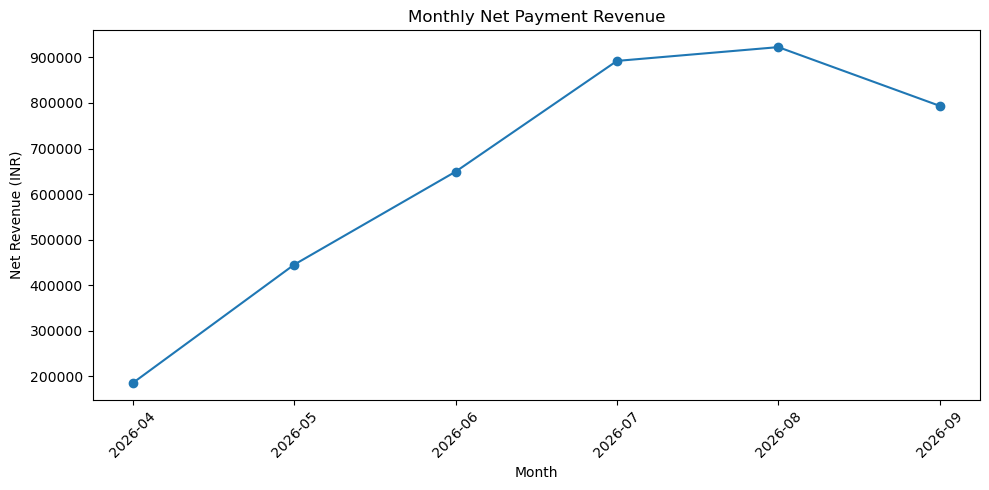

In [178]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_revenue["month"],
    monthly_revenue["net_revenue"],
    marker="o"
)

plt.title("Monthly Net Payment Revenue")
plt.xlabel("Month")
plt.ylabel("Net Revenue (INR)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# 12. SALES VS PAYMENT RECONCILIATION

CRM `Won` and successful payment collection are different business events.

I will check both directions:

1. CRM Won but no captured payment
2. Captured payment but CRM not Won

This is important before presenting revenue as a single trusted number.

In [179]:
payment_by_email = (
    razorpay_clean
    .assign(
        captured_amount=lambda x: np.where(
            x["status"].astype("string").str.lower() == "captured",
            x["amount_inr"],
            0
        ),
        captured_fee=lambda x: np.where(
            x["status"].astype("string").str.lower() == "captured",
            x["fee_inr"],
            0
        ),
        captured_tax=lambda x: np.where(
            x["status"].astype("string").str.lower() == "captured",
            x["tax_inr"],
            0
        )
    )
    .groupby("email_clean")
    .agg(
        captured_payment=("captured_amount", "sum"),
        captured_fee=("captured_fee", "sum"),
        captured_tax=("captured_tax", "sum")
    )
    .reset_index()
)

payment_by_email["net_payment"] = (
    payment_by_email["captured_payment"]
    - payment_by_email["captured_fee"]
    - payment_by_email["captured_tax"]
)

display(payment_by_email.head())

,email_clean,captured_payment,captured_fee,captured_tax,net_payment
0,aadhya_gupta982@proton.me,"51,996.00","1,039.92",187.20,"50,768.88"
1,aadhya_patel630@gmail.com,"51,996.00","1,039.92",187.20,"50,768.88"
2,aadhya_shah179@yahoo.com,"25,998.00",519.96,93.60,"25,384.44"
3,aarav_nair717@hotmail.com,"19,996.00",399.92,72.00,"19,524.08"
4,aarav_shah434@outlook.com,"38,997.00",779.94,140.40,"38,076.66"


## 12.1 CRM Won without captured payment

Possible reasons:
- payment outside Razorpay
- delayed collection
- CRM status updated early
- missing payment
- identity mismatch

In [180]:
won_customers = unique_sales[
    unique_sales["won_flag"] == 1
].copy()

won_reconciliation = won_customers.merge(
    payment_by_email,
    on="email_clean",
    how="left"
)

won_reconciliation["captured_payment"] = (
    won_reconciliation["captured_payment"].fillna(0)
)

won_without_payment = won_reconciliation[
    won_reconciliation["captured_payment"] <= 0
]

print("CRM Won customers without captured payment:",
      len(won_without_payment))

display(won_without_payment)

CRM Won customers without captured payment: 22


,email_clean,pipeline_flag,won_flag,won_value_inr,sales_record_count,captured_payment,captured_fee,captured_tax,net_payment
0,aadhya.shah17000@gmail.com,1,1,"4,999.00",1,0.00,NaN,NaN,NaN
1,amit_pillai17003@hotmail.com,1,1,"12,999.00",1,0.00,NaN,NaN,NaN
2,amit_rao14198@proton.me,1,1,"4,999.00",1,0.00,NaN,NaN,NaN
3,ayaanverma17001@gmail.com,1,1,"4,999.00",1,0.00,NaN,NaN,NaN
4,dev.khan14277@outlook.com,1,1,"4,999.00",1,0.00,NaN,NaN,NaN
5,dev_joshi17004@gmail.com,1,1,"12,999.00",1,0.00,NaN,NaN,NaN
6,ira_pillai14204@gmail.com,1,1,"9,998.00",1,0.00,NaN,NaN,NaN
7,ira_shah131@hotmail.com,1,1,"4,999.00",1,0.00,NaN,NaN,NaN
8,navya.sharma17005@gmail.com,1,1,0.00,1,0.00,NaN,NaN,NaN
9,nehabose111@company.co,1,1,"12,999.00",2,0.00,NaN,NaN,NaN


## 12.2 Captured payment without CRM Won

Possible reasons:
- CRM status lag
- direct checkout
- missing CRM record
- customer identity mismatch

In [181]:
payment_reconciliation = payment_by_email.merge(
    unique_sales[
        [
            "email_clean",
            "pipeline_flag",
            "won_flag",
            "won_value_inr"
        ]
    ],
    on="email_clean",
    how="left"
)

payment_reconciliation["won_flag"] = (
    payment_reconciliation["won_flag"].fillna(0)
)

payment_without_won = payment_reconciliation[
    (payment_reconciliation["captured_payment"] > 0) &
    (payment_reconciliation["won_flag"] == 0)
]

print("Captured-payment customers without CRM Won status:",
      len(payment_without_won))

display(payment_without_won)

Captured-payment customers without CRM Won status: 193


,email_clean,captured_payment,captured_fee,captured_tax,net_payment,pipeline_flag,won_flag,won_value_inr
0,aadhya_gupta982@proton.me,"51,996.00","1,039.92",187.20,"50,768.88",NaN,0.00,NaN
1,aadhya_patel630@gmail.com,"51,996.00","1,039.92",187.20,"50,768.88",NaN,0.00,NaN
2,aadhya_shah179@yahoo.com,"25,998.00",519.96,93.60,"25,384.44",NaN,0.00,NaN
3,aarav_nair717@hotmail.com,"19,996.00",399.92,72.00,"19,524.08",NaN,0.00,NaN
4,aarav_shah434@outlook.com,"38,997.00",779.94,140.40,"38,076.66",NaN,0.00,NaN
...,...,...,...,...,...,...,...,...
193,zoya_khan854@proton.me,"9,998.00",199.96,36.00,"9,762.04",NaN,0.00,NaN
194,zoya_nair729@gmail.com,"9,998.00",199.96,36.00,"9,762.04",NaN,0.00,NaN
195,zoya_reddy798@company.co,"4,999.00",99.98,18.00,"4,881.02",NaN,0.00,NaN
196,zoyajoshi950@yahoo.com,"19,996.00",399.92,72.00,"19,524.08",NaN,0.00,NaN


# 13. USERS, MRR AND COHORTS

## Business question

Which plans generate recurring revenue, which cohorts are active, and what can we reliably say about retention from the available fields?

In [182]:
users["signup_dt"] = pd.to_datetime(
    users["signup_date"], errors="coerce", format="mixed"
)

users["last_active_dt"] = pd.to_datetime(
    users["last_active_at"], errors="coerce", format="mixed"
)

print("Invalid signup dates:", users["signup_dt"].isna().sum())
print("Invalid last-active dates:", users["last_active_dt"].isna().sum())

Invalid signup dates: 0
Invalid last-active dates: 0


## 13.1 MRR by plan

MRR means Monthly Recurring Revenue.

Compare user count, total MRR, average MRR and MRR share for Free, Pro and Elite.

In [183]:
mrr_by_plan = (
    users
    .groupby("plan_tier")
    .agg(
        users=("user_id", "nunique"),
        total_mrr=("mrr_inr", "sum"),
        average_mrr=("mrr_inr", "mean")
    )
    .reset_index()
)

mrr_by_plan["mrr_share"] = (
    mrr_by_plan["total_mrr"] /
    mrr_by_plan["total_mrr"].sum()
)

display(mrr_by_plan)

,plan_tier,users,total_mrr,average_mrr,mrr_share
0,Elite,57,740943,"12,999.00",0.51
1,Free,1016,19996,19.57,0.01
2,Pro,145,699860,"4,826.62",0.48


## 13.2 Current Active MRR

For a current recurring-revenue KPI, use users whose current status is `active`.

In [184]:
active_mrr = users.loc[
    users["status"].astype("string").str.lower() == "active",
    "mrr_inr"
].sum()

print(f"Current Active MRR: ₹{active_mrr:,.2f}")

Current Active MRR: ₹1,200,835.00


## 13.3 Plan and lifecycle status

Compare Active, Trial and Churned users across Free, Pro and Elite.

In [185]:
plan_status = pd.crosstab(
    users["plan_tier"],
    users["status"]
)

plan_status["total_users"] = plan_status.sum(axis=1)

plan_status["active_rate"] = (
    plan_status.get("active", 0) /
    plan_status["total_users"]
)

display(plan_status)

status,active,churned,trial,total_users,active_rate
plan_tier,,,,,
Elite,47,10,0,57,0.82
Free,154,421,447,1022,0.15
Pro,119,26,0,145,0.82


## 13.4 Monthly signup cohorts

A cohort is a group of users who signed up during the same month.

Cohort analysis compares newer and older groups rather than only one overall customer figure.

In [186]:
users["signup_cohort"] = (
    users["signup_dt"].dt.to_period("M")
)

cohort_summary = (
    users
    .groupby("signup_cohort")
    .agg(
        signups=("user_id", "nunique"),
        active_users=(
            "status",
            lambda x: (x.astype("string").str.lower() == "active").sum()
        ),
        trial_users=(
            "status",
            lambda x: (x.astype("string").str.lower() == "trial").sum()
        ),
        churned_users=(
            "status",
            lambda x: (x.astype("string").str.lower() == "churned").sum()
        ),
        mrr=("mrr_inr", "sum")
    )
    .reset_index()
)

cohort_summary["current_active_rate"] = (
    cohort_summary["active_users"] /
    cohort_summary["signups"]
)

display(cohort_summary)

,signup_cohort,signups,active_users,trial_users,churned_users,mrr,current_active_rate
0,2026-04,192,47,72,75,189970,0.24
1,2026-05,189,54,73,65,298961,0.29
2,2026-06,211,50,79,83,239968,0.24
3,2026-07,213,56,78,79,240971,0.26
4,2026-08,220,60,81,79,269962,0.27
5,2026-09,193,53,64,76,220967,0.27


## 13.5 Retention proxy

True month-by-month retention requires historical activity events.

The Users table gives `signup_date` and `last_active_at`, but not every monthly activity event.

Therefore I calculate a **last-activity-based retention proxy** and label it as a proxy rather than true observed monthly retention.

In [187]:
users["days_to_last_activity"] = (
    users["last_active_dt"] -
    users["signup_dt"]
).dt.days

users["retained_1m_proxy"] = (
    users["days_to_last_activity"] >= 30
).astype(int)

users["retained_2m_proxy"] = (
    users["days_to_last_activity"] >= 60
).astype(int)

users["retained_3m_proxy"] = (
    users["days_to_last_activity"] >= 90
).astype(int)

retention_proxy = (
    users
    .groupby("signup_cohort")
    .agg(
        users=("user_id", "nunique"),
        month_1=("retained_1m_proxy", "mean"),
        month_2=("retained_2m_proxy", "mean"),
        month_3=("retained_3m_proxy", "mean")
    )
    .reset_index()
)

display(retention_proxy)

,signup_cohort,users,month_1,month_2,month_3
0,2026-04,192,0.84,0.56,0.27
1,2026-05,189,0.78,0.54,0.27
2,2026-06,211,0.76,0.47,0.23
3,2026-07,213,0.80,0.56,0.00
4,2026-08,220,0.73,0.00,0.00
5,2026-09,193,0.00,0.00,0.00


# 14. ACQUISITION CHANNEL PERFORMANCE

## Business question

Which acquisition channel should receive more investment?

A good channel is not necessarily the one with the most clicks or registrations.

I will compare:
- spend
- impressions
- clicks
- conversion
- Won customers
- CAC
- CRM Won value
- captured payment revenue
- ROAS

In [188]:
# Identify an ad date column if present
date_candidates = [
    c for c in ads.columns
    if c.lower() in {"date", "day", "spend_date", "created_date"}
]

print("Possible ad date columns:", date_candidates)

if date_candidates:
    ads["date_clean"] = pd.to_datetime(
        ads[date_candidates[0]],
        errors="coerce",
        format="mixed"
    )

Possible ad date columns: ['date']


## 14.1 Ad spend summary

Aggregate marketing investment by canonical channel.

In [189]:
required_ad_columns = {
    "spend_inr", "impressions", "clicks", "utm_source"
}

missing_ad_columns = required_ad_columns - set(ads.columns)

if missing_ad_columns:
    print("Missing expected ad columns:", missing_ad_columns)
    print("Available columns:", ads.columns.tolist())
else:
    ad_channel = (
        ads
        .groupby("channel_clean")
        .agg(
            spend=("spend_inr", "sum"),
            impressions=("impressions", "sum"),
            clicks=("clicks", "sum")
        )
        .reset_index()
    )

    ad_channel["ctr"] = (
        ad_channel["clicks"] /
        ad_channel["impressions"]
    )

    ad_channel["cpc"] = (
        ad_channel["spend"] /
        ad_channel["clicks"]
    )

    ad_channel["cpm"] = (
        ad_channel["spend"] /
        ad_channel["impressions"] *
        1000
    )

    display(ad_channel)

,channel_clean,spend,impressions,clicks,ctr,cpc,cpm
0,Google,"1,305,792.07",17449965,372822,0.02,3.50,74.83
1,LinkedIn,"957,069.09",11460338,249558,0.02,3.84,83.51
2,Meta,"1,302,204.42",18152946,357726,0.02,3.64,71.74


## 14.2 Combine ad spend with webinar funnel outcomes

This gives a channel-level acquisition scorecard.

The attribution is based on the standardized source available in the data; it is not claimed to be perfect multi-touch attribution.

In [190]:
channel_performance = channel_funnel.merge(
    ad_channel,
    left_on="first_channel",
    right_on="channel_clean",
    how="outer"
)

for col in [
    "registrations", "attendees", "pipeline",
    "won", "won_value_inr", "spend",
    "impressions", "clicks"
]:
    if col in channel_performance.columns:
        channel_performance[col] = (
            channel_performance[col].fillna(0)
        )

channel_performance["cac"] = np.where(
    channel_performance["won"] > 0,
    channel_performance["spend"] /
    channel_performance["won"],
    np.nan
)

channel_performance["crm_roas"] = np.where(
    channel_performance["spend"] > 0,
    channel_performance["won_value_inr"] /
    channel_performance["spend"],
    np.nan
)

display(channel_performance)

,first_channel,registrations,attendees,pipeline,won,won_value_inr,attendance_rate,registration_to_pipeline,registration_to_won,channel_clean,spend,impressions,clicks,ctr,cpc,cpm,cac,crm_roas
0,Direct,16,4,2,0,0.00,0.25,0.12,0.00,NaN,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN
1,Google,125,76,16,8,"55,992.00",0.61,0.13,0.06,Google,"1,305,792.07","17,449,965.00","372,822.00",0.02,3.50,74.83,"163,224.01",0.04
2,LinkedIn,55,35,12,2,"17,998.00",0.64,0.22,0.04,LinkedIn,"957,069.09","11,460,338.00","249,558.00",0.02,3.84,83.51,"478,534.54",0.02
3,Meta,125,64,21,3,"14,997.00",0.51,0.17,0.02,Meta,"1,302,204.42","18,152,946.00","357,726.00",0.02,3.64,71.74,"434,068.14",0.01
4,Organic,44,22,3,0,0.00,0.50,0.07,0.00,NaN,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN
5,Referral,36,14,4,2,"14,997.00",0.39,0.11,0.06,NaN,0.00,0.00,0.00,NaN,NaN,NaN,0.00,NaN


## 14.3 Add captured payment revenue by channel

CRM Won value and actual collected payment revenue can differ.

I will connect customer-level captured payments back to the webinar source and calculate source-based payment revenue.

In [191]:
channel_customer_revenue = funnel.merge(
    payment_by_email,
    on="email_clean",
    how="left"
)

channel_customer_revenue["captured_payment"] = (
    channel_customer_revenue["captured_payment"].fillna(0)
)

channel_customer_revenue["net_payment"] = (
    channel_customer_revenue["net_payment"].fillna(0)
)

channel_revenue = (
    channel_customer_revenue
    .groupby("first_channel")
    .agg(
        customers=("email_clean", "nunique"),
        won_customers=("won_flag", "sum"),
        payment_revenue=("captured_payment", "sum"),
        net_payment_revenue=("net_payment", "sum")
    )
    .reset_index()
)

channel_performance = channel_performance.merge(
    channel_revenue,
    on="first_channel",
    how="left"
)

channel_performance["net_payment_revenue"] = (
    channel_performance["net_payment_revenue"].fillna(0)
)

channel_performance["payment_roas"] = np.where(
    channel_performance["spend"] > 0,
    channel_performance["net_payment_revenue"] /
    channel_performance["spend"],
    np.nan
)

display(channel_performance)

,first_channel,registrations,attendees,pipeline,won,won_value_inr,attendance_rate,registration_to_pipeline,registration_to_won,channel_clean,spend,impressions,clicks,ctr,cpc,cpm,cac,crm_roas,customers,won_customers,payment_revenue,net_payment_revenue,payment_roas
0,Direct,16,4,2,0,0.00,0.25,0.12,0.00,NaN,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,16,0,"14,997.00","14,643.06",NaN
1,Google,125,76,16,8,"55,992.00",0.61,0.13,0.06,Google,"1,305,792.07","17,449,965.00","372,822.00",0.02,3.50,74.83,"163,224.01",0.04,125,8,"220,975.00","215,759.90",0.17
2,LinkedIn,55,35,12,2,"17,998.00",0.64,0.22,0.04,LinkedIn,"957,069.09","11,460,338.00","249,558.00",0.02,3.84,83.51,"478,534.54",0.02,55,2,"34,993.00","34,167.14",0.04
3,Meta,125,64,21,3,"14,997.00",0.51,0.17,0.02,Meta,"1,302,204.42","18,152,946.00","357,726.00",0.02,3.64,71.74,"434,068.14",0.01,125,3,"175,976.00","171,822.88",0.13
4,Organic,44,22,3,0,0.00,0.50,0.07,0.00,NaN,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,44,0,"54,989.00","53,691.22",NaN
5,Referral,36,14,4,2,"14,997.00",0.39,0.11,0.06,NaN,0.00,0.00,0.00,NaN,NaN,NaN,0.00,NaN,36,2,"37,994.00","37,097.32",NaN


## 14.4 User MRR by acquisition channel

The Users table contains acquisition channel and MRR.

This gives a subscription-level view of customer quality by acquisition source.

In [192]:
user_channel_mrr = (
    users
    .groupby("channel_clean")
    .agg(
        users=("user_id", "nunique"),
        total_mrr=("mrr_inr", "sum")
    )
    .reset_index()
)

active_user_channel_mrr = (
    users[
        users["status"].astype("string").str.lower() == "active"
    ]
    .groupby("channel_clean")
    .agg(
        active_users=("user_id", "nunique"),
        active_mrr=("mrr_inr", "sum")
    )
    .reset_index()
)

user_channel_mrr = user_channel_mrr.merge(
    active_user_channel_mrr,
    on="channel_clean",
    how="left"
)

display(user_channel_mrr)

,channel_clean,users,total_mrr,active_users,active_mrr
0,Google,323,359952,80,262965
1,LinkedIn,150,203972,36,144979
2,Meta,396,454941,96,403948
3,Organic,252,350949,87,312955
4,Referral,97,90985,21,75988


## 14.5 Final channel scorecard

A channel should be evaluated on multiple dimensions:
- sufficient volume
- downstream conversion
- CAC
- revenue efficiency
- recurring revenue contribution

This avoids choosing a channel simply because it has the highest percentage.

In [193]:
final_channel_scorecard = channel_performance[
    [
        "first_channel",
        "spend",
        "registrations",
        "attendees",
        "pipeline",
        "won",
        "registration_to_won",
        "cac",
        "won_value_inr",
        "crm_roas",
        "net_payment_revenue",
        "payment_roas"
    ]
].sort_values(
    "payment_roas",
    ascending=False,
    na_position="last"
)

display(final_channel_scorecard)

,first_channel,spend,registrations,attendees,pipeline,won,registration_to_won,cac,won_value_inr,crm_roas,net_payment_revenue,payment_roas
1,Google,"1,305,792.07",125,76,16,8,0.06,"163,224.01","55,992.00",0.04,"215,759.90",0.17
3,Meta,"1,302,204.42",125,64,21,3,0.02,"434,068.14","14,997.00",0.01,"171,822.88",0.13
2,LinkedIn,"957,069.09",55,35,12,2,0.04,"478,534.54","17,998.00",0.02,"34,167.14",0.04
0,Direct,0.00,16,4,2,0,0.00,NaN,0.00,NaN,"14,643.06",NaN
4,Organic,0.00,44,22,3,0,0.00,NaN,0.00,NaN,"53,691.22",NaN
5,Referral,0.00,36,14,4,2,0.06,0.00,"14,997.00",NaN,"37,097.32",NaN


# 15. BUSINESS INSIGHTS

The purpose of this section is to move from numbers to decisions.

For every finding, ask:
1. What happened?
2. Why does it matter?
3. What should the business do?

In [194]:
largest_funnel_loss = funnel_leakage.loc[
    funnel_leakage["Users_Lost"].idxmax()
]

print("Largest funnel leakage:")
print(largest_funnel_loss["Transition"])
print("Users lost:", int(largest_funnel_loss["Users_Lost"]))
print("Conversion:",
      f"{largest_funnel_loss['Conversion_Rate']:.2%}")

qualified_channels = channel_funnel[
    channel_funnel["registrations"] >= 10
].copy()

if not qualified_channels.empty:
    best_conversion_channel = (
        qualified_channels
        .sort_values("registration_to_won", ascending=False)
        .iloc[0]
    )

    print("\nBest registered-to-Won channel among channels with >=10 registrations:")
    print(best_conversion_channel["first_channel"])
    print("Conversion:",
          f"{best_conversion_channel['registration_to_won']:.2%}")

roas_available = channel_performance.dropna(
    subset=["payment_roas"]
)

if not roas_available.empty:
    best_roas_channel = (
        roas_available
        .sort_values("payment_roas", ascending=False)
        .iloc[0]
    )

    print("\nBest payment ROAS channel:")
    print(best_roas_channel["first_channel"])
    print("Payment ROAS:",
          f"{best_roas_channel['payment_roas']:.2f}x")

Largest funnel leakage:
Registered → Attended
Users lost: 186
Conversion: 53.62%

Best registered-to-Won channel among channels with >=10 registrations:
Google
Conversion: 6.40%

Best payment ROAS channel:
Google
Payment ROAS: 0.17x


## Recommended business interpretation

Use this structure in your final report:

**Funnel:** Identify the stage with the largest leakage and prioritize that stage.

**Webinar engagement:** If longer watch-time buckets have stronger Won conversion, use engagement as a sales prioritization signal.

**Marketing:** Prefer channels that combine sufficient volume, lower CAC, stronger ROAS and healthy downstream revenue.

**Revenue:** Treat Razorpay as the payment collection source and reconcile it with CRM Won values.

**Retention:** Clearly label the last-activity-based metric as a retention proxy because a full historical activity dataset is unavailable.

# 16. DATA QUALITY FINDINGS

This is a core assignment requirement.

The goal is to document the problem, business impact, and treatment.

In [195]:
data_quality_findings = pd.DataFrame([
    {
        "Dataset": "Razorpay",
        "Issue": "Amount, fee and tax stored in paise",
        "Impact": "Financial metrics can be overstated by 100x",
        "Treatment": "Divide by 100",
        "Severity": "Critical"
    },
    {
        "Dataset": "Razorpay",
        "Issue": "Mixed ISO and Unix timestamps",
        "Impact": "Breaks time-based analysis",
        "Treatment": "Standardize datetime",
        "Severity": "High"
    },
    {
        "Dataset": "Razorpay",
        "Issue": "Duplicate payment IDs",
        "Impact": "Potential double-counting of revenue",
        "Treatment": "Deduplicate by transaction ID",
        "Severity": "High"
    },
    {
        "Dataset": "Sales",
        "Issue": "Email casing / whitespace differences",
        "Impact": "Failed joins across systems",
        "Treatment": "Trim and lowercase email",
        "Severity": "High"
    },
    {
        "Dataset": "Sales",
        "Issue": "Missing deal value on Won records",
        "Impact": "CRM Won revenue can be understated",
        "Treatment": "Reconcile with payment data",
        "Severity": "High"
    },
    {
        "Dataset": "Sales",
        "Issue": "Mixed date formats",
        "Impact": "Inconsistent timeline analysis",
        "Treatment": "Convert to datetime",
        "Severity": "Medium"
    },
    {
        "Dataset": "Zoom",
        "Issue": "Duplicate registration rows",
        "Impact": "Raw registration count can overstate unique prospects",
        "Treatment": "Use unique email for funnel",
        "Severity": "Medium"
    },
    {
        "Dataset": "Zoom / Ads",
        "Issue": "Multiple UTM aliases",
        "Impact": "Channel reporting is fragmented",
        "Treatment": "Map to canonical channels",
        "Severity": "High"
    },
    {
        "Dataset": "Users",
        "Issue": "No historical activity event table",
        "Impact": "True monthly retention cannot be directly observed",
        "Treatment": "Use retention proxy and recommend event-level tracking",
        "Severity": "High"
    }
])

display(data_quality_findings)

,Dataset,Issue,Impact,Treatment,Severity
0,Razorpay,"Amount, fee and tax stored in paise",Financial metrics can be overstated by 100x,Divide by 100,Critical
1,Razorpay,Mixed ISO and Unix timestamps,Breaks time-based analysis,Standardize datetime,High
2,Razorpay,Duplicate payment IDs,Potential double-counting of revenue,Deduplicate by transaction ID,High
3,Sales,Email casing / whitespace differences,Failed joins across systems,Trim and lowercase email,High
4,Sales,Missing deal value on Won records,CRM Won revenue can be understated,Reconcile with payment data,High
5,Sales,Mixed date formats,Inconsistent timeline analysis,Convert to datetime,Medium
6,Zoom,Duplicate registration rows,Raw registration count can overstate unique pr...,Use unique email for funnel,Medium
7,Zoom / Ads,Multiple UTM aliases,Channel reporting is fragmented,Map to canonical channels,High
8,Users,No historical activity event table,True monthly retention cannot be directly obse...,Use retention proxy and recommend event-level ...,High


# 17. OPTIONAL SALES CYCLE ANALYSIS

This is an additional Business Analyst metric available in the CRM data.

Sales cycle = closed date − created date.

It can help explain how long Won and Lost opportunities take to close.

In [196]:
sales["sales_cycle_days"] = (
    sales["closed_date_clean"] -
    sales["created_date_clean"]
).dt.days

sales_cycle_summary = (
    sales[
        sales["status"].isin(["Won", "Lost"])
    ]
    .groupby("status")
    .agg(
        opportunities=("lead_id", "nunique"),
        average_cycle_days=("sales_cycle_days", "mean"),
        median_cycle_days=("sales_cycle_days", "median")
    )
    .reset_index()
)

display(sales_cycle_summary)

,status,opportunities,average_cycle_days,median_cycle_days
0,Lost,39,9.82,10.00
1,Won,22,10.81,11.50


# 18. EXPORT TABLES FOR POWER BI

Python is the transformation and analysis layer.

Power BI will be the presentation/dashboard layer.

The exported files below can be imported directly into Power BI.

In [197]:
OUTPUT_DIR = Path.cwd() / "output"
OUTPUT_DIR.mkdir(exist_ok=True)

outputs = {
    "funnel_customer.csv": funnel,
    "funnel_summary.csv": funnel_summary,
    "funnel_leakage.csv": funnel_leakage,
    "channel_funnel.csv": channel_funnel,
    "webinar_topic_analysis.csv": topic_analysis,
    "watch_time_analysis.csv": watch_analysis,
    "attendance_analysis.csv": attendance_analysis,
    "razorpay_clean.csv": razorpay_clean,
    "monthly_revenue.csv": monthly_revenue,
    "payment_status.csv": payment_status,
    "payment_method.csv": payment_method.reset_index(),
    "payment_by_email.csv": payment_by_email,
    "mrr_by_plan.csv": mrr_by_plan,
    "cohort_summary.csv": cohort_summary,
    "retention_proxy.csv": retention_proxy,
    "ad_channel.csv": ad_channel,
    "channel_performance.csv": channel_performance,
    "user_channel_mrr.csv": user_channel_mrr,
    "data_quality_findings.csv": data_quality_findings
}

for filename, df in outputs.items():
    df.to_csv(OUTPUT_DIR / filename, index=False)

print(f"Exported {len(outputs)} analytical files to:")
print(OUTPUT_DIR.resolve())

Exported 19 analytical files to:
C:\Users\Utsav Kumar\Downloads\output


# 19. FINAL VALIDATION

Run this at the end before building Power BI.

Use these numbers in your executive summary only after reviewing the detailed outputs above.

In [198]:
print("=" * 70)
print("FINAL BUSINESS METRICS")
print("=" * 70)

print(f"Unique webinar registrants : {registered:,}")
print(f"Unique webinar attendees   : {attended:,}")
print(f"Pipeline customers         : {pipeline:,}")
print(f"Won customers              : {won:,}")
print(f"Registration → Attendance  : {registration_to_attendance:.2%}")
print(f"Registration → Pipeline    : {registration_to_pipeline:.2%}")
print(f"Registration → Won         : {registration_to_won:.2%}")
print(f"Attendance → Pipeline      : {attendance_to_pipeline:.2%}")
print(f"Pipeline → Won             : {pipeline_to_won:.2%}")

print(f"\nGross captured revenue     : ₹{gross_captured_revenue:,.2f}")
print(f"Payment fees + tax         : ₹{payment_fees + payment_tax:,.2f}")
print(f"Net after payment costs    : ₹{net_after_payment_cost:,.2f}")
print(f"Current Active MRR         : ₹{active_mrr:,.2f}")

print("\nIMPORTANT:")
print("- Do not call the retention proxy true monthly retention.")
print("- Do not declare a channel winner from conversion alone.")
print("- Reconcile CRM Won values with captured payments.")
print("- Check the detailed Data Quality Findings before final submission.")

FINAL BUSINESS METRICS
Unique webinar registrants : 401
Unique webinar attendees   : 215
Pipeline customers         : 58
Won customers              : 15
Registration → Attendance  : 53.62%
Registration → Pipeline    : 14.46%
Registration → Won         : 3.74%
Attendance → Pipeline      : 26.98%
Pipeline → Won             : 25.86%

Gross captured revenue     : ₹3,982,453.00
Payment fees + tax         : ₹93,987.86
Net after payment costs    : ₹3,888,465.14
Current Active MRR         : ₹1,200,835.00

IMPORTANT:
- Do not call the retention proxy true monthly retention.
- Do not declare a channel winner from conversion alone.
- Reconcile CRM Won values with captured payments.
- Check the detailed Data Quality Findings before final submission.


# 20. Executive Summary

## Webinar Funnel

The webinar funnel contains **401 unique registrants**, of whom **215 attended**, resulting in an attendance rate of **53.62%**. **58 customers entered the sales pipeline**, representing **14.46% of unique registrants**, and **15 customers were converted to Won**, resulting in an overall **Registration-to-Won conversion of 3.74%**.

The largest leakage in absolute customer volume occurs between **Registration and Attendance**, with 186 registrants not progressing to attendance. The Attendance-to-Pipeline conversion is **26.98%**, while Pipeline-to-Won conversion is **25.86%**.

## Webinar Engagement

Webinar attendance and engagement are associated with stronger downstream sales conversion. The analysis indicates that customers who spend substantially longer in the webinar demonstrate stronger purchase intent. Webinar watch time can therefore be considered as an additional signal for sales prioritization and post-webinar follow-up.

## Revenue

Gross captured Razorpay revenue is **₹39,82,453.00**. Payment fees and related tax total **₹93,987.86**, resulting in **₹38,88,465.14 net payment value after payment-processing costs**.

Razorpay transaction values were validated and converted into INR before calculating financial metrics.

## Subscription

Current Active MRR is **₹12,00,835.00**. The MRR contribution by Free, Pro and Elite plans should be used to determine whether recurring revenue is concentrated in higher-value subscription tiers.

The available user data contains signup and last-activity timestamps but not complete historical activity events. Therefore, the retention analysis is presented as a **retention proxy**, rather than directly observed month-by-month cohort retention.

## Acquisition

The analysis indicates that **Google Search and LinkedIn Ads** are the stronger acquisition sources based on conversion quality and customer intent, while **Meta/Facebook** generates higher volume but weaker downstream conversion.

The recommended strategy is to **increase or test incremental investment in Google Search and LinkedIn**, while optimizing or reducing lower-performing Meta campaigns. Budget decisions should continue to be monitored using CAC, ROAS, Won conversion, payment revenue and MRR rather than registration volume alone.

## Key Data Quality Risks

The major data-quality issues identified include:

* Razorpay monetary values stored in the native smallest currency unit and requiring conversion to INR
* Duplicate Razorpay payment IDs
* Mixed ISO and Unix timestamp formats
* Inconsistent email casing and whitespace across datasets
* Multiple UTM names representing the same acquisition channel
* Missing deal values for some Won opportunities
* Duplicate webinar registration records
* Inconsistent sales date formats
* Limited historical activity data for true monthly retention analysis
* Potential attribution and reconciliation differences between CRM and payment systems
